# **Exploring Factors Linked to Heart Disease**

### **Group Members:**
1. Ramith Wijesinghe
2. Brian Liu
3. Zhuoxin Xia

## **Introduction**

Heart disease is a broad term for problems that affect the function of the heart. Various conditions can make it more challenging for the heart to pump blood around the body.
Factors linked to heart disease such as high blood pressure, smoking, and diabetes are important because they can raise a person’s risk and help guide prevention and treatment.

## **Topic**
This project aims to examine how gender, existing health conditions, exercise habits, and other lifestyle factors could be associated with heart disease. The dataset we chose is a CDC annual survey in 2022 asking about the health status of over 400k+ adults. Included in the dataset are responses to various questions such as age, BMI, smoking frequency, and other potential factors that may share a connection with heart disease.

In [1]:
# necessary libraries
import pandas as pd
import numpy as np
import requests
import seaborn as sns
import sqlite3
import matplotlib.pyplot as plt

In [2]:
# pull csv file for 2022 
df = pd.read_csv("health.csv")

# we create a copy to compare with after cleaning
df_raw = df.copy()
df.head()

,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,...,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
0,Alabama,Female,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,No,8.0,NaN,No,...,NaN,NaN,NaN,No,No,Yes,No,"Yes, received tetanus shot but not sure what type",No,No
1,Alabama,Female,Excellent,0.0,0.0,NaN,No,6.0,NaN,No,...,1.60,68.04,26.57,No,No,No,No,"No, did not receive any tetanus shot in the pa...",No,No
2,Alabama,Female,Very good,2.0,3.0,Within past year (anytime less than 12 months ...,Yes,5.0,NaN,No,...,1.57,63.50,25.61,No,No,No,No,NaN,No,Yes
3,Alabama,Female,Excellent,0.0,0.0,Within past year (anytime less than 12 months ...,Yes,7.0,NaN,No,...,1.65,63.50,23.30,No,No,Yes,Yes,"No, did not receive any tetanus shot in the pa...",No,No
4,Alabama,Female,Fair,2.0,0.0,Within past year (anytime less than 12 months ...,Yes,9.0,NaN,No,...,1.57,53.98,21.77,Yes,No,No,Yes,"No, did not receive any tetanus shot in the pa...",No,No


# **Data Processing and Cleaning**

In [3]:
print(df.shape)

(445132, 40)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 445132 entries, 0 to 445131
Data columns (total 40 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   State                      445132 non-null  object 
 1   Sex                        445132 non-null  object 
 2   GeneralHealth              443934 non-null  object 
 3   PhysicalHealthDays         434205 non-null  float64
 4   MentalHealthDays           436065 non-null  float64
 5   LastCheckupTime            436824 non-null  object 
 6   PhysicalActivities         444039 non-null  object 
 7   SleepHours                 439679 non-null  float64
 8   RemovedTeeth               433772 non-null  object 
 9   HadHeartAttack             442067 non-null  object 
 10  HadAngina                  440727 non-null  object 
 11  HadStroke                  443575 non-null  object 
 12  HadAsthma                  443359 non-null  object 
 13  HadSkinCancer              44

In [5]:
# get unique values of each feature and their count
for c in df.select_dtypes(include=["object", "string"]).columns:
    if df[c].nunique() <= 12 and c != "State":
        print("\n"+ c)
        print(df[c].value_counts(dropna=False))


Sex
Sex
Female    235893
Male      209239
Name: count, dtype: int64

GeneralHealth
GeneralHealth
Very good    148444
Good         143598
Excellent     71878
Fair          60273
Poor          19741
NaN            1198
Name: count, dtype: int64

LastCheckupTime
LastCheckupTime
Within past year (anytime less than 12 months ago)         350944
Within past 2 years (1 year but less than 2 years ago)      41919
Within past 5 years (2 years but less than 5 years ago)     24882
5 or more years ago                                         19079
NaN                                                          8308
Name: count, dtype: int64

PhysicalActivities
PhysicalActivities
Yes    337559
No     106480
NaN      1093
Name: count, dtype: int64

RemovedTeeth
RemovedTeeth
None of them              233455
1 to 5                    129294
6 or more, but not all     45570
All                        25453
NaN                        11360
Name: count, dtype: int64

HadHeartAttack
HadHeartAttack
No     4169

### **Diplicate Entries**

We want to first check if there are any entries that are exact duplicates of others. Depending on the dataset, it may actually be natural to have entries with the same data such as real world logs. In our case we will remove any duplicates because reponses to the survey are unique to each individual.

In [6]:
# check for duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 157


In [7]:
before_row = len(df)
print(f"Total entries including duplicates: {before_row}")

# now we will remove the duplicate rows and reset index
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before_row - len(df)} duplicate rows.")
print(f"Total entries after removal: {len(df)}")

Total entries including duplicates: 445132
Removed 157 duplicate rows.
Total entries after removal: 444975


### **Missing Values**

Next we want to examine how many unrecorded values there are for each feature. Depending on the total amount we may want to remove them or potentially calculate estimates to fill in the missing values.

In [8]:
# get nul vals per feature
null_vals = df.isnull().sum()
print(null_vals)

# represent nul vals as a percentage
null_vals_pct = ( null_vals / len(df) * 100).round(2)
print(null_vals_pct[null_vals_pct > 0].sort_values(ascending=False))

State                            0
Sex                              0
GeneralHealth                 1193
PhysicalHealthDays           10922
MentalHealthDays              9062
LastCheckupTime               8301
PhysicalActivities            1088
SleepHours                    5448
RemovedTeeth                 11355
HadHeartAttack                3060
HadAngina                     4400
HadStroke                     1552
HadAsthma                     1768
HadSkinCancer                 3138
HadCOPD                       2214
HadDepressiveDisorder         2807
HadKidneyDisease              1921
HadArthritis                  2628
HadDiabetes                   1082
DeafOrHardOfHearing          20502
BlindOrVisionDifficulty      21419
DifficultyConcentrating      24095
DifficultyWalking            23867
DifficultyDressingBathing    23770
DifficultyErrands            25511
SmokerStatus                 35316
ECigaretteUsage              35514
ChestScan                    55900
RaceEthnicityCategor

From the analysis above, we will drop three columns with lots of missing values, and will not be of use for our future analysis. 

- `TetanusLast10Tdap`: 18.54%
- `PneumoVaxEver`: 17.31%
- `HIVTesting`: 14.86%

In [9]:
# drop columns we won't use
df= df.drop(columns = ["TetanusLast10Tdap", "PneumoVaxEver", "HIVTesting"])

### **Convert Categorical Values to Numerical**

For easier computation later, we convert columns with "yes" and "no" values to 1 and 0 repectively. 

In [10]:
# convert "yes" and "no" to 0 and 1s
yes_no_cols = [ c for c in df.columns 
                if set(df[c].dropna().unique()) == {"Yes", "No"}
              ] 
print(yes_no_cols)

for x in yes_no_cols:
    df[x] = df[x].map({"Yes":1, "No":0})

['PhysicalActivities', 'HadHeartAttack', 'HadAngina', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'ChestScan', 'AlcoholDrinkers', 'FluVaxLast12', 'HighRiskLastYear']


### **Simplifying Features**

For features with long or detailed responses we want to simplify them down while capturing the original trends. This is important to improve the dataset's clarity and make analysis simpler.

In [11]:
df["ECigarette"] = df["ECigaretteUsage"].map({      
    "Never used e-cigarettes in my entire life": "Never",
    "Not at all (right now)": "Former",                
    "Use them some days": "Current",
    "Use them every day": "Current"})

df["Smoking"] = df["SmokerStatus"].map({               
    "Never smoked": "Never",
    "Former smoker": "Former",
    "Current smoker - now smokes every day": "Current",
    "Current smoker - now smokes some days": "Current"})

df["CovidPos"] = df["CovidPos"].map({                 
    "No": 0,
    "Yes": 1,
    "Tested positive using home test without a health professional": 1})

df["HadDiabetes"] = df["HadDiabetes"].map({            
    "Yes": "Yes",
    "No": "No",
    "No, pre-diabetes or borderline diabetes": "Pre-diabetes",
    "Yes, but only during pregnancy (female)": "Diabetic at Pregnancy"})

df["LastCheckup"] = df["LastCheckupTime"].map({        
    "Within past year (anytime less than 12 months ago)": "<1 year",
    "Within past 2 years (1 year but less than 2 years ago)": "1-2 years",
    "Within past 5 years (2 years but less than 5 years ago)": "2-5 years",
    "5 or more years ago": "5+ years"})


In [12]:
# since we created three new simplified labels, we remove the old ones
df = df.drop(columns=["SmokerStatus", "ECigaretteUsage", "LastCheckupTime"])  

In [13]:
# viewing the changes
for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- State ---
State
Washington              26142
New York                17784
Minnesota               16816
Ohio                    16482
Maryland                16410
Texas                   14237
Florida                 13385
Wisconsin               11273
Kansas                  11243
Massachusetts           11027
California              10948
Maine                   10646
Indiana                 10459
Virginia                10414
Arizona                 10184
Michigan                10054
South Carolina          10034
Utah                     9823
Connecticut              9771
Colorado                 9361
Georgia                  9234
Iowa                     8948
Vermont                  8801
New Jersey               8196
Hawaii                   7747
Nebraska                 7472
Missouri                 7438
South Dakota             7423
Montana                  7047
New Hampshire            6754
Idaho                    6280
Rhode Island             5891
Alaska             

### **Extreme Values**
We look into near impossible values that do not make sense and leave them as missing so they will be handled as blank values.

Adults shorter than 1.2 m or taller than 2.3 m are likely errors.

Weights outside 30–300 kg are extreme outliers

Sleep hours less than 2 or greater than 16 are highly unlikely.

In [14]:
limits = {"HeightInMeters": (1.2, 2.3),                
          "WeightInKilograms": (30, 300),
          "SleepHours": (2, 16)}

In [15]:
for col, (low, high) in limits.items():               
    bad = (df[col] < low) | (df[col] > high)           
    print(col, "extreme values:", bad.sum())        
    df.loc[bad, col] = np.nan 

HeightInMeters extreme values: 143
WeightInKilograms extreme values: 72
SleepHours extreme values: 1601


### **Calculating the Unkown BMI**

As BMI simply uses weight and height for its calculation we can fill in any missing BMIs, provided the respondent has their weight and height.

In [16]:
# BMI calculation equation
bmi_eq = (df["WeightInKilograms"] / df["HeightInMeters"] ** 2).round(2)

# nul BMIs that can be calculated
print("BMI recoverable:", (df["BMI"].isnull() & bmi_eq.notnull()).sum())

# check for BMIs that do not match calculated answer
print("BMI mismatch:", ((df["BMI"] - bmi_eq).abs() > 0.5).sum())

# filling the missing BMI
df["BMI"] = df["BMI"].fillna(bmi_eq)

BMI recoverable: 2177
BMI mismatch: 7


### **Creating the Target HeartDisease Feature**

Now we create the target variable that takes both HadHeartAttack and HadAngina and summarise it as having a HeartDisease

In [17]:
df["HeartDisease"] = np.nan
df.loc[(df["HadHeartAttack"] == 0) & (df["HadAngina"] == 0), "HeartDisease"] = 0
df.loc[(df["HadHeartAttack"] == 1) | (df["HadAngina"] == 1), "HeartDisease"] = 1
print(df["HeartDisease"].value_counts(dropna=False))

HeartDisease
0.0    400208
1.0     39751
NaN      5016
Name: count, dtype: int64


We remove columns with blank HeartDisease since this is the outcome we are going to study. We won't fill in the NaN outcomes as that could create false conclusions

In [18]:
before = len(df)
df = df.dropna(subset=["HeartDisease"]).reset_index(drop=True) 
df["HeartDisease"] = df["HeartDisease"].astype(int) 
print("Dropped: ", before - len(df))
df = df.drop(columns=["HadHeartAttack", "HadAngina"])

Dropped:  5016


### **Data Imputation**

With certain features we may be able to fill them in with the median, mode, or other imputations. Filling in the missing values can be beneficial to the analysis as it allows for machine learning models to train on the features. Also, simply dropping all entries with missing values can introduce bias and bring wrong conclusions.

In [19]:
# change age category into a numerical format
lo = df["AgeCategory"].str.extract(r"Age (\d+)")[0].astype(float)   
hi = df["AgeCategory"].str.extract(r"to (\d+)")[0].astype(float)    
df["AgeMid"] = ((lo + hi) / 2).fillna(lo + 2)                       
df[["AgeCategory", "AgeMid"]].drop_duplicates().sort_values("AgeMid")
df["AgeCategory"] = df["AgeCategory"].fillna("Unknown")

df["AgeMid"] = df["AgeMid"].fillna(df["AgeMid"].median())

In [20]:
# now we look into other columns that might have blanks and fill them up
num_cols = ["PhysicalHealthDays", "MentalHealthDays", "SleepHours",
            "HeightInMeters", "WeightInKilograms", "BMI"]

for c in num_cols:                                                       
    group_median = df.groupby(["Sex", "AgeMid"])[c].transform("median")  
    df[c] = df[c].fillna(group_median)                                   
    df[c] = df[c].fillna(df[c].median())                                 

text_cols = ["PhysicalActivities", "HadStroke", "HadAsthma", "HadSkinCancer", "HadCOPD",
               "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis", "DeafOrHardOfHearing",
               "BlindOrVisionDifficulty", "DifficultyConcentrating", "DifficultyWalking",
               "DifficultyDressingBathing", "DifficultyErrands", "ChestScan", "AlcoholDrinkers",
               "FluVaxLast12", "HighRiskLastYear", "CovidPos"]
for c in text_cols:
    most_common = df[c].mode()[0]            
    df[c] = df[c].fillna(most_common)        
    df[c] = df[c].astype(int)

missing_cols = ["GeneralHealth", "RemovedTeeth", "HadDiabetes", "Smoking",
            "ECigarette", "LastCheckup", "RaceEthnicityCategory", "AgeCategory"]
for c in missing_cols:
    df[c] = df[c].fillna("Unknown")

print("Missing: ", df.isnull().sum().sum())

Missing:  0


**Now we save the cleaned data set**


In [21]:
# remove any duplicates created in the process
df = df.drop_duplicates().reset_index(drop=True) 
df.to_csv("health_clean.csv", index=False) 

In [22]:
print("Raw shape  :", df_raw.shape)                 
print("Clean shape:", df.shape)                     
print("Missing values:", df.isnull().sum().sum())  
print("Duplicates    :", df.duplicated().sum())   

Raw shape  : (445132, 40)
Clean shape: (439890, 37)
Missing values: 0
Duplicates    : 0


# **Exploratory Data Analysis (EDA)**

### **Smoking Status vs. Heart Disease**

In [23]:
# Compare smoking groups
order = ["Never", "Former", "Current"]

smoking_data = df[df["Smoking"].isin(order)]

rates = (
    smoking_data.groupby("Smoking")["HeartDisease"]
    .mean()
    .reindex(order) * 100
)

print(rates.round(2))

Smoking
Never       6.56
Former     13.58
Current    11.55
Name: HeartDisease, dtype: float64


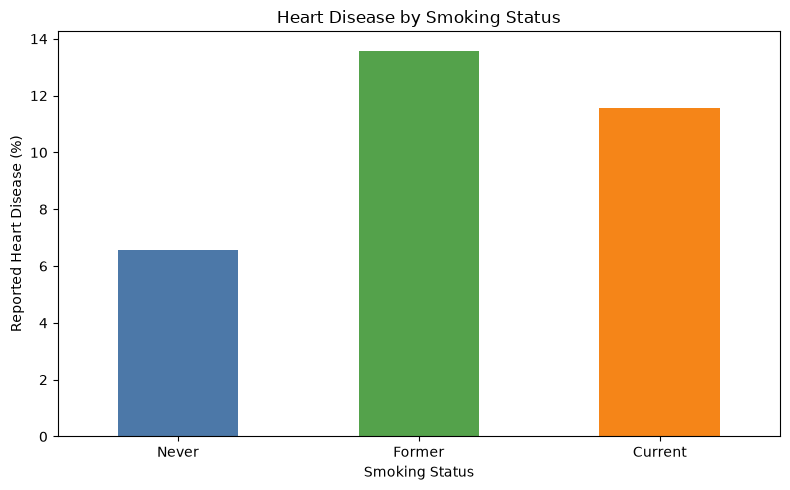

In [24]:
# Visualize the group percentages
plt.figure(figsize=(8, 5))

rates.plot(kind="bar", color=["#4C78A8", "#54A24B", "#F58518"])

plt.title("Heart Disease by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Reported Heart Disease (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

We use a chi-square test to determine if the proportion of individuals in at least one of the smoking groups is meaningfully different from the others.

H$_{0}$: Smoking status and heart disease are independent

H$_{a}$: At least one smoking group has a different proportion of people with heart disease

In [25]:
from scipy.stats import chi2_contingency

# Create a contingency table
table = pd.crosstab(
    smoking_data["Smoking"],
    smoking_data["HeartDisease"]
)

# Run Chi-square test
chi2, p_value, dof, expected = chi2_contingency(table)

print(table)
print("Chi-square:", chi2)
print("p-value:", p_value)

HeartDisease       0      1
Smoking                    
Current        43535   5686
Former         97111  15265
Never         227717  15993
Chi-square: 4978.885839276863
p-value: 0.0


Based on our results, people who never smoked had the lowest heart disease rate (6.56%), while former smokers had the highest (13.58%). The chi-square test also showed a significant relationship (p < 0.001). This suggests that smoking status is associated with heart disease, but other factors like age and health conditions may also affect the results.

### **BMI vs. Heart Disease**

In [26]:
# Compare BMI between two groups
bmi_data = df[["HeartDisease", "BMI"]].dropna()

print(
    bmi_data.groupby("HeartDisease")["BMI"]
    .agg(["count", "mean", "median"])
    .round(2)
)

               count   mean  median
HeartDisease                       
0             400139  28.32   27.46
1              39751  29.28   28.06


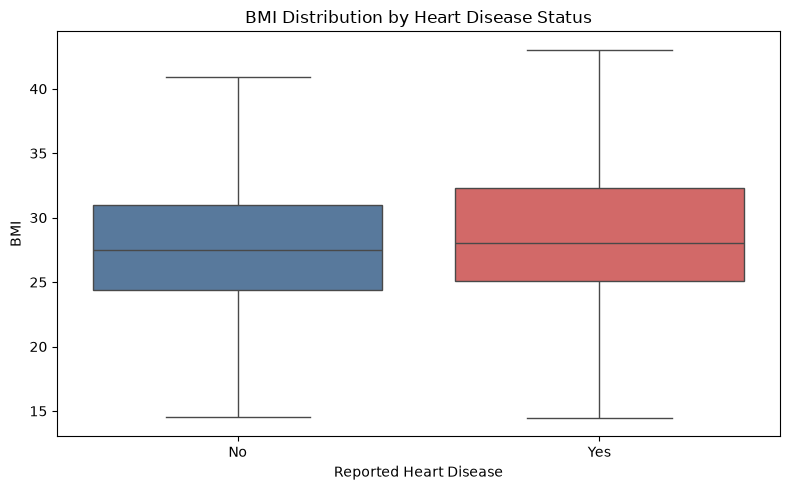

In [27]:
# Visualize BMI distribution
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=bmi_data,
    x="HeartDisease",
    y="BMI",
    order=[0, 1],
    showfliers=False,
    hue="HeartDisease",
    palette={0: "#4C78A8", 1: "#E45756"},
    legend=False
)

plt.title("BMI Distribution by Heart Disease Status")
plt.xlabel("Reported Heart Disease")
plt.ylabel("BMI")
plt.xticks([0, 1], ["No", "Yes"])

plt.tight_layout()
plt.show()

We perform a Mann-Whitney U test and examine if BMI has an effect on heart disease.

H$_{0}$: There is no statistical difference in the BMI between people with heart disease and those without

H$_{a}$: There is a statistical difference in the BMI between people with heart disease and those without

In [28]:
from scipy.stats import mannwhitneyu

# Separate BMI values by heart disease status
bmi_no = bmi_data[bmi_data["HeartDisease"] == 0]["BMI"]
bmi_yes = bmi_data[bmi_data["HeartDisease"] == 1]["BMI"]

# Run Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    bmi_no, bmi_yes, alternative="two-sided"
)

print("U statistic:", u_stat)
print("p-value:", p_value)

U statistic: 7189966451.5
p-value: 3.834669746072446e-219


Our results show that people who reported heart disease had a slightly higher average BMI (29.28 vs. 28.32). The Mann–Whitney U test also showed a significant difference (p < 0.001). However, the difference is relatively small, so BMI alone may not explain heart disease.

### **Age vs. Heart Disease**

In [29]:
# Calculate heart disease rates by age group
age_data = df[df["AgeCategory"] != "Unknown"]

age_summary = (
    age_data.groupby(["AgeCategory", "AgeMid"], as_index=False)
    .agg(
        count=("HeartDisease", "size"),
        rate=("HeartDisease", "mean")
    )
    .sort_values("AgeMid")
)

age_summary["rate_pct"] = age_summary["rate"] * 100

print(age_summary[["AgeCategory", "count", "rate_pct"]].round(2))

        AgeCategory  count  rate_pct
0      Age 18 to 24  26742      0.75
1      Age 25 to 29  21867      0.97
2      Age 30 to 34  25649      1.22
3      Age 35 to 39  28327      1.66
4      Age 40 to 44  29720      2.37
5      Age 45 to 49  28305      3.77
6      Age 50 to 54  33348      5.46
7      Age 55 to 59  36462      7.92
8      Age 60 to 64  44006     10.01
9      Age 65 to 69  46548     12.58
10     Age 70 to 74  42929     15.86
11     Age 75 to 79  31973     19.42
12  Age 80 or older  35285     23.29


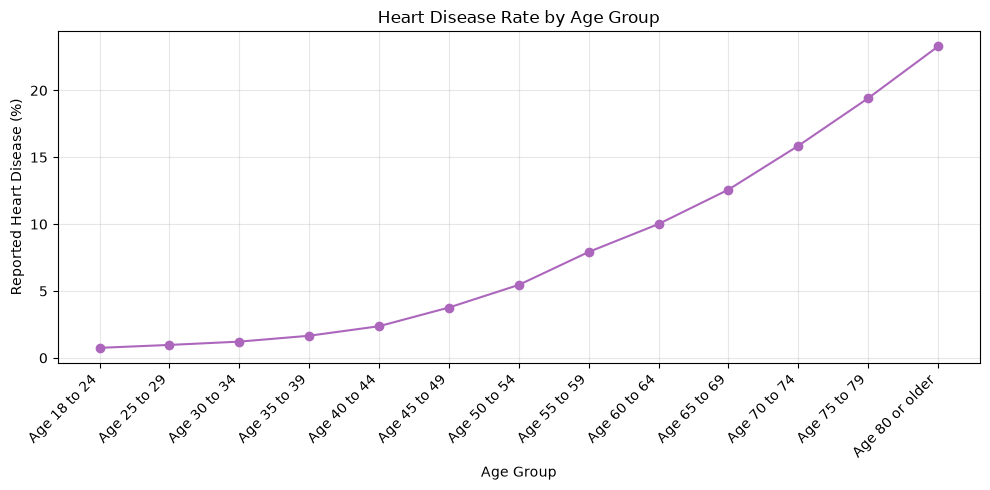

In [30]:
# Visualize heart disease rates across age groups
plt.figure(figsize=(10, 5))

plt.plot(
    age_summary["AgeCategory"],
    age_summary["rate_pct"],
    marker="o",
    color="#AC67BD"
)

plt.title("Heart Disease Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Reported Heart Disease (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

We perform a Spearman rank correlation test to find if there is a correlation between age and heart disease.

H$_{0}$: There is no correlation between age and heart disease

H$_{a}$: The is a correlation between age and heart disease

In [31]:
from scipy.stats import spearmanr

# Prepare data for correlation test
age_test = age_data[["AgeMid", "HeartDisease"]].dropna()

# Run Spearman correlation
rho, p_value = spearmanr(
    age_test["AgeMid"],
    age_test["HeartDisease"]
)

print("Spearman correlation:", rho)
print("p-value:", p_value)

Spearman correlation: 0.2436612176664864
p-value: 0.0


Our results show that the reported heart disease rate increases with age, from 0.75% for ages 18–24 to 23.29% for people aged 80 and older. The Spearman test also showed a significant positive correlation (ρ = 0.244, p < 0.001). This suggests that age is associated with heart disease, although other health factors may also play a role.